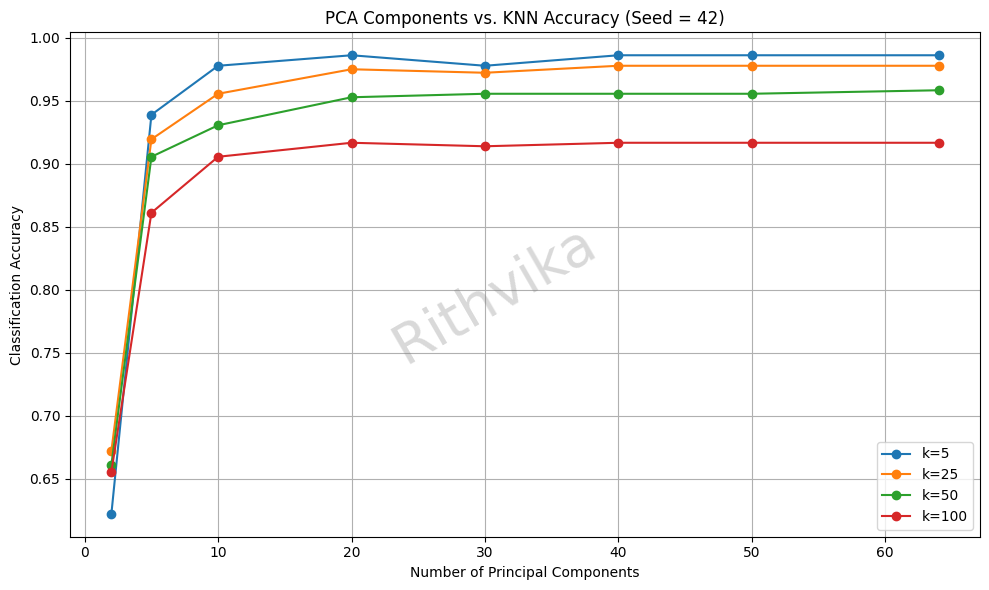

In [ ]:
# --------------------------------------------
# Q6: PCA + KNN Classification (using seed=42)
# --------------------------------------------

# === Imports ===
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

from pca import CustomPCA

# === Set random seed ===
seed = 42
np.random.seed(seed)

# === Load 8x8 Digits Dataset ===
"""
The dataset consists of 1797 grayscale images of handwritten digits (0–9).  
Each image is 8x8 pixels, flattened into a 64-dimensional feature vector.
"""
digits = load_digits()
X = digits.data     # shape (1797, 64)
y = digits.target   # labels 0–9

# === Train-Test Split (80-20 with seed=42) ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# === PCA Dimensions to Try ===
"""
We reduce dimensionality of the dataset to different numbers of principal components.
This allows us to compare how much information is retained at different compression levels.
"""
n_components_list = [2, 5, 10, 20, 30, 40, 50, 64]

# Dictionary to store transformed data
pca_results = {}

for n_components in n_components_list:
    """
    Apply PCA transformation with `n_components` principal components.
    Store the transformed training and test sets for later KNN evaluation.
    """
    pca = CustomPCA(n_components=n_components)
    pca.fit(X_train)

    X_train_pca = pca.transform(X_train)
    X_test_pca = pca.transform(X_test)

    pca_results[n_components] = (X_train_pca, X_test_pca)

# === KNN Evaluation ===
k_values = [5, 25, 50, 100]
accuracy_results = {}

for n_components in n_components_list:
    X_train_pca, X_test_pca = pca_results[n_components]

    for k in k_values:
        """
        Train KNN classifier with k neighbors and compute accuracy on test data.
        Store results in a dictionary for later visualization.
        """
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_train_pca, y_train)

        y_pred = knn.predict(X_test_pca)
        acc = accuracy_score(y_test, y_pred)

        accuracy_results[(n_components, k)] = acc

# === Plot Accuracy vs Number of Components ===
plt.figure(figsize=(10, 6))

for k in k_values:
    accs = [accuracy_results[(n, k)] for n in n_components_list]
    plt.plot(n_components_list, accs, marker='o', label=f'k={k}')

plt.xlabel('Number of Principal Components')
plt.ylabel('Classification Accuracy')
plt.title('PCA Components vs. KNN Accuracy (Seed = 42)')
plt.legend()
plt.grid(True)
plt.text(0.5, 0.5, 'Rithvika',
         transform=plt.gcf().transFigure,
         fontsize=40, color='gray', alpha=0.3,
         ha='center', va='center', rotation=30)
plt.tight_layout()
plt.show()


### Observations: PCA Components vs. KNN Accuracy

#### 1. Effect of Number of Principal Components on KNN Accuracy
- As the number of principal components increases from **2 to 20**, the **classification accuracy improves significantly** for all values of `k`.
- Beyond **20–30 components**, the accuracy **plateaus**, indicating that most of the useful information is captured by these components.
- Adding more components beyond this point leads to **diminishing returns** — there's **little to no improvement** in classification accuracy.

#### Key Insight:
> The **first 20–30 principal components** capture the majority of the information needed for effective classification on the digits dataset.

---

#### 2. Effect of `k` in KNN on Accuracy
- Lower values of `k` (like **k = 5**) tend to achieve **higher peak accuracy**, but can be more **sensitive to noise** or small variations.
- As `k` increases:
  - Accuracy generally **decreases slightly**.
  - The model becomes **more stable**, but possibly less flexible to data nuances.
- For example:
  - At 20 components:
    - `k = 5` gives the **highest accuracy** (~0.98).
    - `k = 100` gives the **lowest accuracy** (~0.92).

####  Key Insight:
> Smaller `k` values tend to perform better in this PCA-KNN setup, but larger `k` values may generalize better in some noisy or larger datasets.

---

#### 3. Diminishing Returns with PCA Dimensions
- After about **30–40 principal components**, all curves flatten out, meaning:
  - Additional components **do not significantly boost accuracy**.
  - This marks the **point of diminishing returns**.
  - It’s computationally efficient to use fewer components without losing performance.

#### Key Insight:
> **Using all 64 features** is unnecessary — a compact representation using **20–30 components** achieves nearly **optimal accuracy**.

- The results are **specific to this small dataset**. For higher-dimensional data, the number of required components may increase, and the optimal `k` value could differ.

---

#### Summary

| Observation                                      | Conclusion                                |
|--------------------------------------------------|--------------------------------------------|
| Accuracy increases quickly up to ~20 components | Most variance is captured early            |
| Accuracy plateaus beyond ~30 components         | Diminishing returns                        |
| Smaller `k` (e.g., 5) achieves higher accuracy   | More sensitive but effective               |
| Larger `k` (e.g., 100) is more stable            | Slightly less accurate                     |

---
